# Predikcija kategorije proizvoda na osnovu naslova
**Luka Krestalica — Task 3**

Cilj je predlaganje jedne od deset kategorija iz naslova. Izvor je dostavljeni `IMLP6_TASK_03-products.csv`, sačuvan bez izmene kao `data/products.csv`. Ostale kolone koristimo za pregled kvaliteta, ali ne za predikciju: pri unosu korisnik ima samo naslov.

Pokrenuti svesku iz korena projekta nakon instalacije `requirements.txt`. Run All ponovo trenira modele i osvežava `models/` i `reports/`. Rezultati u sačuvanoj svesci potiču iz stvarnog izvršavanja.

In [1]:
from pathlib import Path
import json, pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import ConfusionMatrixDisplay
from train_model import load_data, run_training, make_model, LABELS
from product_features import TitleStats
ROOT = Path.cwd()
assert (ROOT / 'data/products.csv').is_file(), 'Otvorite svesku iz korena projekta.'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

## Pregled i kvalitet podataka
Pregledamo tipove, prazna polja i raspodelu oznaka. Naslovi nisu svi na istom jeziku i sadrže brendove i kodove modela; zato ne uklanjamo brojeve niti primenjujemo listu engleskih stop reči.

In [2]:
raw, clean, cleaning = load_data(ROOT / 'data/products.csv')
print('Izvorni oblik:', raw.shape)
display(raw.head())
raw.info()
display(raw.isna().sum().rename('Prazna polja').to_frame())
display(raw['Category Label'].value_counts(dropna=False).rename('Broj').to_frame())
print(json.dumps(cleaning, ensure_ascii=False, indent=2))

Izvorni oblik: (35311, 8)
<class 'pandas.DataFrame'>
RangeIndex: 35311 entries, 0 to 35310
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   product ID       35311 non-null  int64  
 1   Product Title    35139 non-null  str    
 2   Merchant ID      35311 non-null  int64  
 3   Category Label   35267 non-null  str    
 4   _Product Code    35216 non-null  str    
 5   Number_of_Views  35297 non-null  float64
 6   Merchant Rating  35141 non-null  float64
 7   Listing Date     35252 non-null  str    
dtypes: float64(2), int64(2), str(4)
memory usage: 2.2 MB
{
  "raw_rows": 35311,
  "missing_by_column": {
    "product ID": 0,
    "Product Title": 172,
    "Merchant ID": 0,
    "Category Label": 44,
    "_Product Code": 95,
    "Number_of_Views": 14,
    "Merchant Rating": 170,
    "Listing Date": 59
  },
  "raw_categories": {
    "Fridge Freezers": 5495,
    "Washing Machines": 4036,
    "Mobile Phones": 4020,


,product ID,Product Title,Merchant ID,Category Label,_Product Code,Number_of_Views,Merchant Rating,Listing Date
0,1,apple iphone 8 plus 64gb silver,1,Mobile Phones,QA-2276-XC,860.0,2.5,5/10/2024
1,2,apple iphone 8 plus 64 gb spacegrau,2,Mobile Phones,KA-2501-QO,3772.0,4.8,12/31/2024
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,Mobile Phones,FP-8086-IE,3092.0,3.9,11/10/2024
3,4,apple iphone 8 plus 64gb space grey,4,Mobile Phones,YI-0086-US,466.0,3.4,5/2/2022
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,Mobile Phones,NZ-3586-WP,4426.0,1.6,4/12/2023


,Prazna polja
product ID,0
Product Title,172
Merchant ID,0
Category Label,44
_Product Code,95
Number_of_Views,14
Merchant Rating,170
Listing Date,59


,Broj
Category Label,
Fridge Freezers,5495
Washing Machines,4036
Mobile Phones,4020
CPUs,3771
TVs,3564
Fridges,3457
Dishwashers,3418
Digital Cameras,2696
Microwaves,2338


## Čišćenje i sprečavanje curenja podataka
Ujednačene su oznake `CPU → CPUs`, `fridge → Fridges`, `Mobile Phone → Mobile Phones`, uz uklanjanje spoljašnjih razmaka. Redovi bez naslova ili ciljne oznake uklanjaju se; nedostajući pregledi ili ocena prodavca nisu razlog za uklanjanje jer nisu ulazi modela.

Za isti naslov zanemarujemo veličinu slova i višestruke razmake pri poređenju. Uklanjamo protivrečno označene tekstove i preostale duplikate pre podele, da isti tekst ne bude u obe grupe. Slične varijante istog artikla ipak mogu ostati: ova evaluacija ne garantuje generalizaciju na potpuno nove familije proizvoda.

,title,category,key
0,apple iphone 8 plus 64gb silver,Mobile Phones,apple iphone 8 plus 64gb silver
1,apple iphone 8 plus 64 gb spacegrau,Mobile Phones,apple iphone 8 plus 64 gb spacegrau
2,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,Mobile Phones,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...
3,apple iphone 8 plus 64gb space grey,Mobile Phones,apple iphone 8 plus 64gb space grey
4,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,Mobile Phones,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...


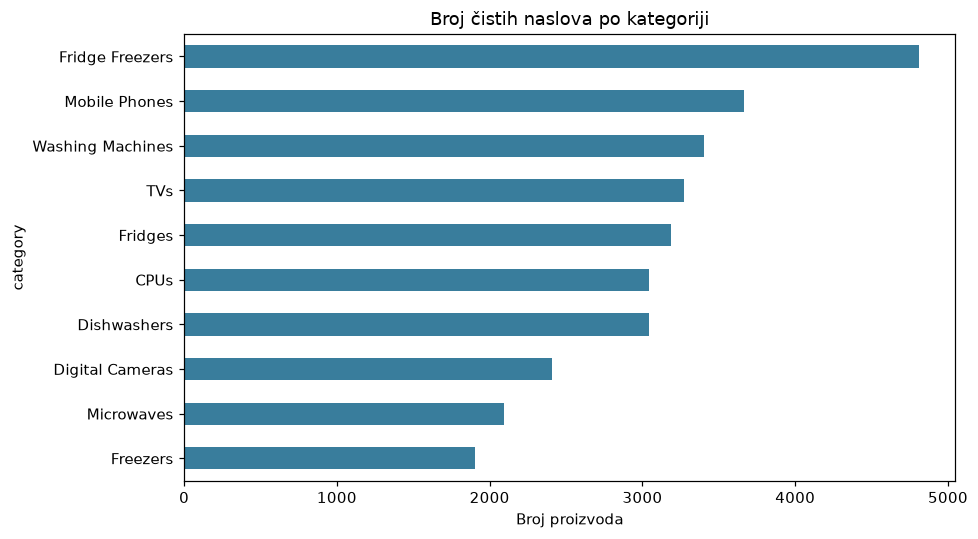

In [3]:
display(clean.head())
clean['category'].value_counts().sort_values().plot.barh(figsize=(9, 5), color='#397d9c')
plt.title('Broj čistih naslova po kategoriji'); plt.xlabel('Broj proizvoda')
plt.tight_layout(); plt.show()

## Inženjering karakteristika i plan eksperimenata
1. Reči i parovi reči, TF-IDF: brendovi i izrazi poput `fridge freezer`.
2. Delovi reči dužine 3–5 znakova (`char_wb`): kodovi modela, varijacije i različiti jezici.
3. Šest numeričkih osobina: broj znakova, reči, cifara, specijalnih znakova, velikih skraćenica i dužina najduže reči. Skalar se uči samo na treningu; doprinos ove grupe smanjen je na 0,15.

Upoređujemo Naive Bayes, logističku regresiju i Linear SVC sa osnovnim karakteristikama, a zatim SVC proširujemo znakovnim i numeričkim osobinama. To omogućava da izmerimo doprinos svake promene. Identifikatori, broj pregleda, datum i prodavac ne ulaze u model.

In [4]:
feature_names = ['characters', 'words', 'digits', 'special_characters', 'uppercase_words', 'longest_word']
display(pd.DataFrame(TitleStats().transform(clean.title.head(8)), columns=feature_names))
display(make_model('SVC_word_char_stats'))

,characters,words,digits,special_characters,uppercase_words,longest_word
0,31.0,6.0,3.0,0.0,0.0,6.0
1,35.0,7.0,3.0,0.0,0.0,9.0
2,70.0,13.0,9.0,2.0,0.0,10.0
3,35.0,7.0,3.0,0.0,0.0,6.0
4,54.0,11.0,6.0,1.0,0.0,8.0
5,36.0,8.0,3.0,0.0,0.0,6.0
6,49.0,10.0,6.0,1.0,0.0,6.0
7,47.0,10.0,3.0,0.0,0.0,6.0


Pipeline(steps=[('features',
                 FeatureUnion(transformer_list=[('word',
                                                 TfidfVectorizer(max_features=30000,
                                                                 min_df=2,
                                                                 ngram_range=(1,
                                                                              2),
                                                                 sublinear_tf=True)),
                                                ('char',
                                                 TfidfVectorizer(analyzer='char_wb',
                                                                 max_features=40000,
                                                                 min_df=2,
                                                                 ngram_range=(3,
                                                                              5),
                                                                 sublinear_tf=True)),
                                                ('stats',
                                                 Pipeline(steps=[('extract',
                                                                  TitleStats()),
                                                                 ('scale',
                                                                  MaxAbsScaler())]))],
                              transformer_weights={'char': 1.0, 'stats': 0.15,
                                                   'word': 1.0})),
                ('classifier', LinearSVC(max_iter=5000, random_state=42))])

## Treniranje i validaciono poređenje
Koristimo stratifikovanu podelu 60% trening / 20% validacija / 20% test, sa semenom 42. Svi kandidati imaju iste skupove. Pipeline uči TF-IDF i skaler samo na trening delu.

Glavni kriterijum je **makro F1**, jer svakoj kategoriji daje jednak značaj. Tačnost razrešava eventualno izjednačenje. Nakon izbora model učimo na treningu i validaciji zajedno, pa jednom ocenjujemo na netaknutom testu. Tek zatim treniramo izdvojeni finalni `.pkl` na svim čistim podacima. Test metrike pripadaju modelu obučenom na 80%, ne nezavisnoj oceni finalnog refita.

NB_word: validation macro-F1=0.9338
LR_word: validation macro-F1=0.9513
SVC_word: validation macro-F1=0.9605
SVC_word_char: validation macro-F1=0.9839
SVC_word_char_stats: validation macro-F1=0.9839
Selected: SVC_word_char_stats; test accuracy=0.9877; macro-F1=0.9877
Izabrani model: SVC_word_char_stats
Veličine skupova: {'train': 18492, 'validation': 6165, 'test': 6165}


,model,accuracy,macro_f1,weighted_f1,seconds
0,NB_word,0.934307,0.933762,0.933881,0.461040
1,LR_word,0.950203,0.951251,0.950023,2.253145
2,SVC_word,0.959448,0.960454,0.959269,0.637079
3,SVC_word_char,0.984266,0.983899,0.984251,2.857970
4,SVC_word_char_stats,0.984266,0.983943,0.984247,3.215725


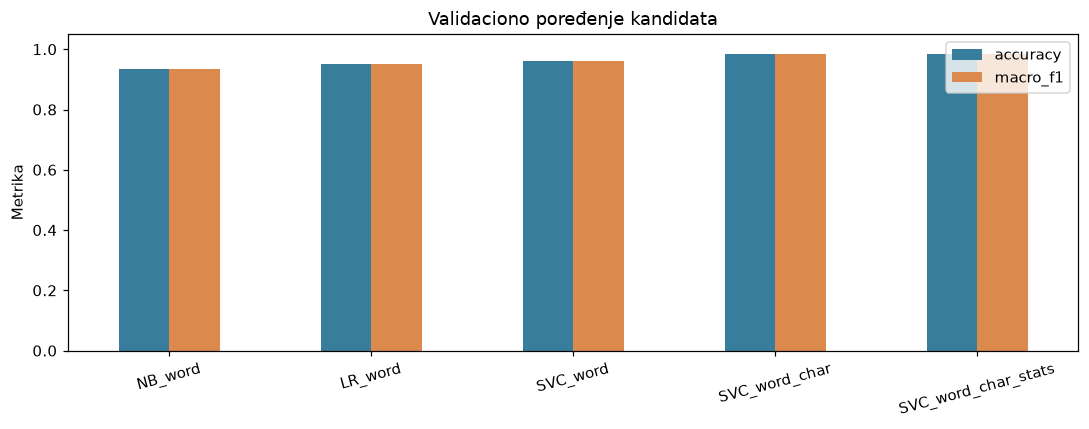

In [5]:
metadata, comparison, report, cm, samples = run_training(ROOT / 'data/products.csv', ROOT)
display(comparison.round(6))
print('Izabrani model:', metadata['selected_model'])
print('Veličine skupova:', metadata['splits'])
comparison.set_index('model')[['accuracy', 'macro_f1']].plot.bar(figsize=(10, 4), ylim=(0, 1.05), rot=15, color=['#397d9c', '#db894c'])
plt.title('Validaciono poređenje kandidata'); plt.ylabel('Metrika'); plt.xlabel('')
plt.tight_layout(); plt.show()

## Evaluacija na test skupu
Prikazujemo precision, recall i F1 po kategoriji, kao i celu matricu zabune. Redovi su stvarne, kolone predviđene kategorije. Većinska pretpostavka daje referencu za tumačenje tačnosti.

Test accuracy: 98.7672%
Test macro F1: 0.987665
Većinska referenca: 15.6042%
Broj test grešaka: 76


,precision,recall,f1-score,support
CPUs,0.9984,0.9951,0.9967,609.0000
Digital Cameras,1.0000,1.0000,1.0000,481.0000
Dishwashers,0.9934,0.9934,0.9934,608.0000
Freezers,0.9787,0.9659,0.9723,381.0000
Fridge Freezers,0.9834,0.9823,0.9828,962.0000
Fridges,0.9492,0.9655,0.9573,638.0000
Microwaves,0.9976,0.9857,0.9916,419.0000
Mobile Phones,0.9946,0.9973,0.9959,732.0000
TVs,0.9969,0.9969,0.9969,655.0000
Washing Machines,0.9897,0.9897,0.9897,680.0000


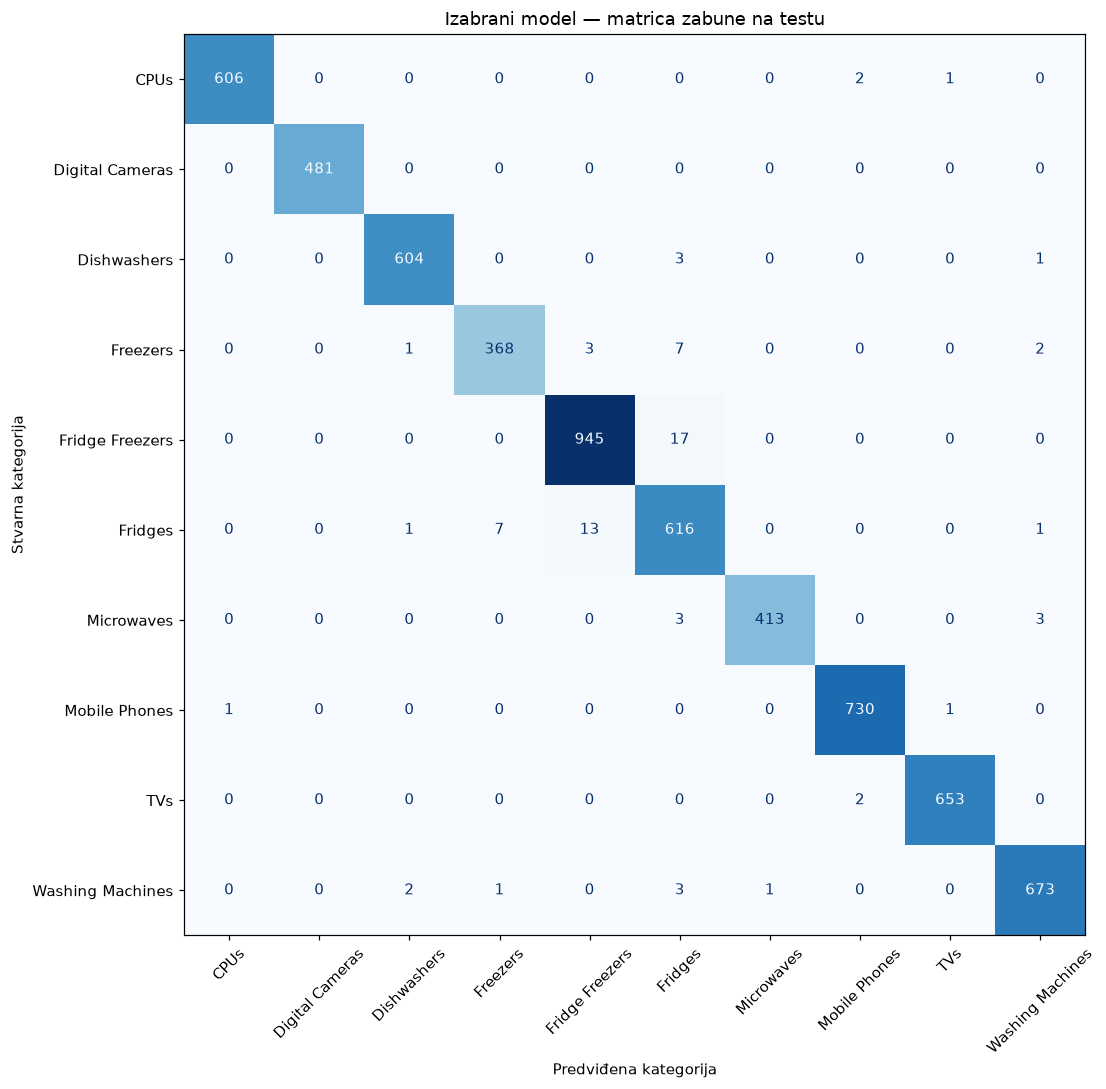

,title,category,predicted
0,zanussi zwy61225wi eek a skala a bis d zwy61225wi,Washing Machines,Fridges
1,bosch stand k hlger t gsn36bi30,Freezers,Fridges
2,montpellier mwbic90044,Microwaves,Fridges
3,blomberg kgm9550p fridge/free,Fridge Freezers,Fridges
4,amica ziv635,Dishwashers,Fridges
5,zanussi zbt20420sa 122cm doppeltrger t eek a s...,Fridge Freezers,Fridges
6,cda fw321/fw321,Fridges,Fridge Freezers
7,gorenje rb3091anw,Fridges,Fridge Freezers
8,montpellier miff7301f,Fridge Freezers,Fridges
9,lenovo phab 2 pro,Mobile Phones,TVs


In [6]:
print(f"Test accuracy: {metadata['test_accuracy']:.4%}")
print(f"Test macro F1: {metadata['test_macro_f1']:.6f}")
print(f"Većinska referenca: {metadata['majority_baseline_accuracy']:.4%}")
display(report.round(4))
fig, ax = plt.subplots(figsize=(12, 10))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap='Blues', xticks_rotation=45, values_format='d', colorbar=False)
ax.set_title('Izabrani model — matrica zabune na testu')
ax.set_xlabel('Predviđena kategorija'); ax.set_ylabel('Stvarna kategorija')
plt.tight_layout(); plt.show()
errors = pd.read_csv(ROOT / 'reports/test_errors.csv')
print('Broj test grešaka:', len(errors))
display(errors.head(12))

## Sačuvani model i ručni primeri
Čuva se kompletan Pipeline, sa rečnikom, skalerom i klasifikatorom. `product_features.py` mora ostati uz skriptove, jer sadrži klasu numeričkih karakteristika. Učitavati samo sopstvene/proverene pickle fajlove.

Šest primera iz zadatka ne koristi se za izbor parametara. Prikazujemo očekivanu i stvarnu predikciju, uključujući greške. Primer koji postoji u trening skupu nije nezavisan test.

In [7]:
with (ROOT / 'models/product_classifier.pkl').open('rb') as f:
    loaded_model = pickle.load(f)
assert (loaded_model.predict(samples.title) == samples.prediction).all()
display(samples)
print(f"Tačni primeri: {samples.correct.sum()}/{len(samples)}")

Tačni primeri: 5/6


,title,expected,prediction,correct,present_in_dataset
0,"iphone 7 32gb gold,4,3,Apple iPhone 7 32GB",Mobile Phones,Mobile Phones,True,False
1,olympus e m10 mark iii geh use silber,Digital Cameras,Digital Cameras,True,True
2,kenwood k20mss15 solo,Microwaves,Microwaves,True,False
3,bosch wap28390gb 8kg 1400 spin,Washing Machines,Washing Machines,True,True
4,bosch serie 4 kgv39vl31g,Fridge Freezers,Fridge Freezers,True,False
5,smeg sbs8004po,Fridge Freezers,Dishwashers,False,False


## Zaključak i zapažanja
Na ovoj validaciji izabran je **SVC_word_char_stats**. Najveći dobitak dolazi od delova reči: makro F1 raste sa oko 0,9605 na 0,9839. Dodavanje numeričkih osobina povećava makro F1 za samo oko **0,000044**, bez promene tačnosti. To je vrlo mala razlika; ne tvrdim da je poboljšanje pouzdano bez dodatnih podela.

Na izdvojenom testu dobijeni su **98,77% tačnosti i makro F1 0,9877**, uz 76 grešaka na 6.165 naslova. Finalni Pipeline zatim je treniran na svih 30.822 čista naslova.

Pet od šest zadatih primera klasifikovano je očekivano. Kratak naslov **`smeg sbs8004po`** model svrstava u **Dishwashers**, dok zadatak očekuje **Fridge Freezers**. Sam brend i nepoznata šifra nisu uvek dovoljni; ovu grešku nisam prikrio pravilom za taj konkretni primer niti dodavanjem test primera u trening.

Sledeći korak bio bi provera na novim familijama proizvoda i novijim oglasima, dodatni validirani primeri kratkih naslova i ručna potvrda nesigurnih predloga. Model uvek bira jednu od poznatih deset klasa i ne može sam pouzdano prepoznati potpuno novu kategoriju.

Dokumentacija: [Pipeline i FeatureUnion](https://scikit-learn.org/stable/modules/compose.html), [čuvanje modela](https://scikit-learn.org/stable/model_persistence.html).